In [14]:
!pip install ultralytics -q

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from ultralytics import YOLO
from google.colab import files

print("YOLOv8 Installed And Ready")

YOLOv8 Installed And Ready


In [2]:
os.makedirs('videos', exist_ok=True)

uploaded = files.upload()
video_path = None

for filename in uploaded.keys():
  video_path = os.path.join('videos', filename)
  os.rename(filename, video_path)
  print(f"Video Saved: {video_path}")

Saving gettyimages-2180240624-640_adpp.mp4 to gettyimages-2180240624-640_adpp.mp4
Video Saved: videos/gettyimages-2180240624-640_adpp.mp4


In [3]:
if not video_path or not os.path.exists(video_path):
  print("No Video Found")
else:
  print("Loading YOLOv8 Nano Model")
  model = YOLO('yolov8n.pt')

  print("Starting Tracking With ByteTrack...")

  results = model.track(
      source=video_path,
      tracker="bytetrack.yaml",
      conf=0.3,
      iou=0.5,
      save=True,
      show=False,
      exist_ok=True
  )

  print("Processing Complete")
  print(f"Output Saved In: runs/detect/track/")

Loading YOLOv8 Nano Model
Starting Tracking With ByteTrack...

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/330) /content/videos/gettyimages-2180240624-640_adpp.mp4: 384x640 2 persons, 1 sports ball, 128.5ms
video 1/1 (frame 2/330) /content/videos/gettyimages-2180240624-640_adpp.mp4: 384x640 2 persons, 105.8ms
video 1/1 (frame 3/330) /content/videos/gettyimages-2180240624-640_adpp.mp4: 384x640 2 persons, 103.7ms
video 1/1 (frame 4/330) /content/videos/gettyimages-2180240624-640_adp

Checking Directory: runs/detect/track
Directory Exists. Contents: ['gettyimages-2180240624-640_adpp.avi', 'gettyimages-558245935-640_adpp.avi']
Output Video Found: runs/detect/track/gettyimages-2180240624-640_adpp.avi
File Size: 12.27 MB


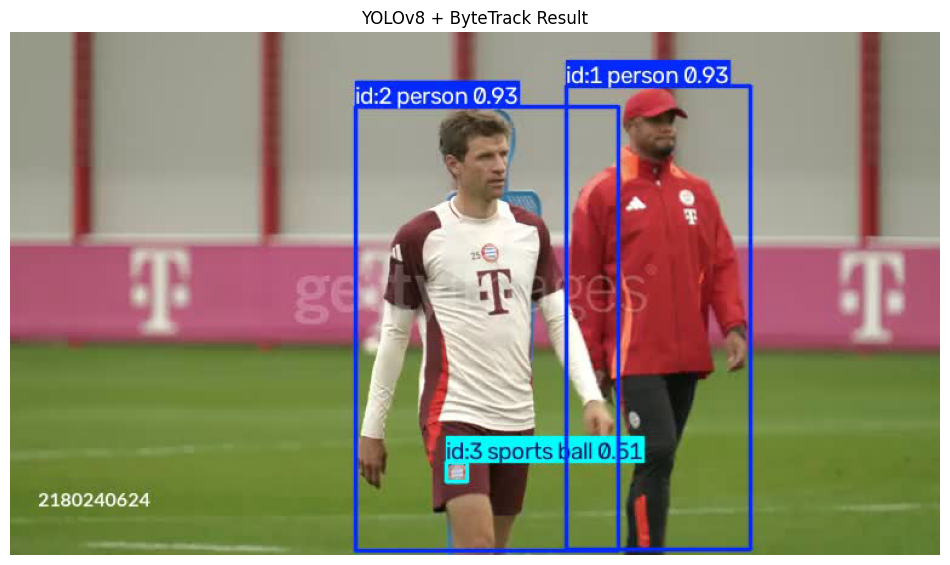

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Video Downloaded Successfully


In [5]:
output_dir = 'runs/detect/track'

print(f"Checking Directory: {output_dir}")

if os.path.exists(output_dir):
    print(f"Directory Exists. Contents: {os.listdir(output_dir)}")

    output_files = [f for f in os.listdir(output_dir) if f.endswith(('.mp4', '.avi', '.mov'))]

    if output_files:
        output_video = os.path.join(output_dir, output_files[0])
        print(f"Output Video Found: {output_video}")
        print(f"File Size: {os.path.getsize(output_video) / (1024*1024):.2f} MB")

        cap = cv2.VideoCapture(output_video)
        ret, frame = cap.read()
        if ret:
            plt.figure(figsize=(12, 8))
            plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            plt.title("YOLOv8 + ByteTrack Result")
            plt.axis('off')
            plt.show()
        cap.release()

        files.download(output_video)
        print("Video Downloaded Successfully")
    else:
        print(f"No Video Files Found In {output_dir}")
        print(f"Directory Contents: {os.listdir(output_dir)}")
else:
    print(f"Output Directory Not Found: {output_dir}")
    print("Please Run Cell 3 First To Process The Video")